# DEEP LEARNING LABORATORY – CO4
**Name:** Harigowtham. A  
**Register Number:** 192324198  
**Course Code:** CSA4708  
**Course Name:** Deep Learning  
**Platform:** Google Colab


In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Libraries imported successfully.")

Libraries imported successfully.


## Experiment 1: PCA and Explained Variance Analysis

**Aim: Apply PCA to image pixel features, calculate explained variance, identify an optimal component count, visualize reduced features, and compare classification performance.**

**Procedure:**
1. Load the Scikit-learn Digits dataset.\n2. Normalize pixel features.\n3. Apply PCA and calculate cumulative explained variance.\n4. Select components retaining at least 95% variance.\n5. Visualize the reduced representation.\n6. Compare Logistic Regression performance using original and reduced features.

Original features: 64 | Components for 95% variance: 30
Variance retained: 0.9543


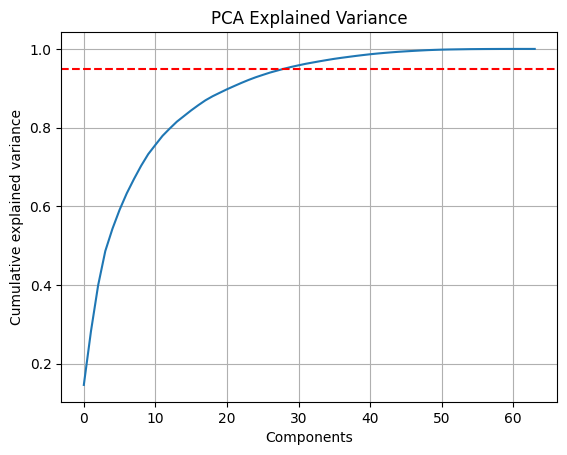

Accuracy using original features: 0.9622
Accuracy using PCA features: 0.9533


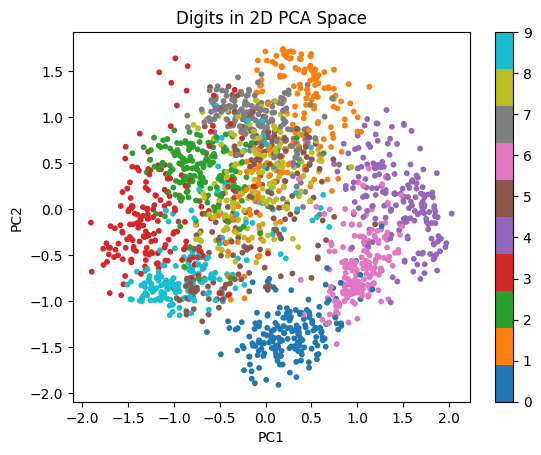

In [2]:
from sklearn.datasets import load_digits
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

digits = load_digits()
X = MinMaxScaler().fit_transform(digits.data)
y = digits.target
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.25, random_state=42, stratify=y)
pca0 = PCA().fit(Xtr)
cum = np.cumsum(pca0.explained_variance_ratio_)
k = np.argmax(cum >= .95) + 1
print("Original features:", X.shape[1], "| Components for 95% variance:", k)
print("Variance retained:", round(cum[k-1], 4))
plt.plot(cum); plt.axhline(.95, color="red", linestyle="--")
plt.xlabel("Components"); plt.ylabel("Cumulative explained variance")
plt.title("PCA Explained Variance"); plt.grid(); plt.show()
pca = PCA(n_components=k)
Xtrp, Xtep = pca.fit_transform(Xtr), pca.transform(Xte)
m1 = LogisticRegression(max_iter=2000).fit(Xtr,ytr)
m2 = LogisticRegression(max_iter=2000).fit(Xtrp,ytr)
print("Accuracy using original features:", round(accuracy_score(yte,m1.predict(Xte)),4))
print("Accuracy using PCA features:", round(accuracy_score(yte,m2.predict(Xtep)),4))
z = PCA(n_components=2).fit_transform(X)
plt.scatter(z[:,0],z[:,1],c=y,cmap="tab10",s=10)
plt.title("Digits in 2D PCA Space"); plt.xlabel("PC1"); plt.ylabel("PC2"); plt.colorbar(); plt.show()

**Output / Results:** The program displays the required numerical results, tables, and visualizations for the experiment.

**Results:** Thus the program was successfully verified.

## Experiment 2: Probabilistic PCA and Reconstruction Analysis

**Aim: Explore probabilistic PCA, extract latent representations, reconstruct images, calculate reconstruction error, and analyze noise variance and log-likelihood.**

**Procedure:**
1. Load and normalize Digits images.\n2. Fit PCA models with different latent dimensions.\n3. Extract latent representations and reconstruct images.\n4. Calculate reconstruction error.\n5. Compare reconstruction quality, estimated noise variance, and log-likelihood.

k=2: MSE=0.05341, noise variance=0.05517, log-likelihood/sample=-0.58232
k=5: MSE=0.03421, noise variance=0.03713, log-likelihood/sample=8.15005
k=10: MSE=0.01994, noise variance=0.02364, log-likelihood/sample=16.38762
k=20: MSE=0.00833, noise variance=0.01212, log-likelihood/sample=25.58044
k=30: MSE=0.00344, noise variance=0.00648, log-likelihood/sample=31.60043


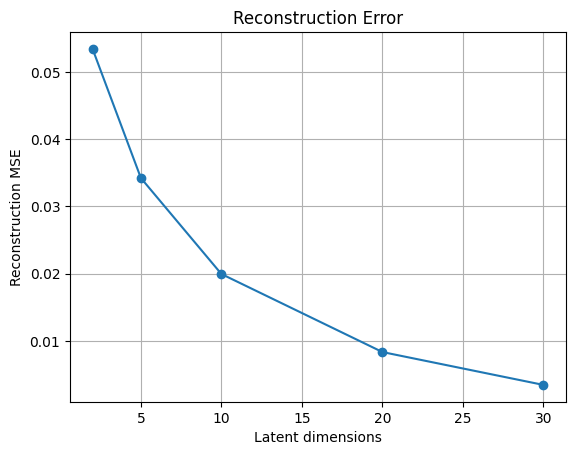

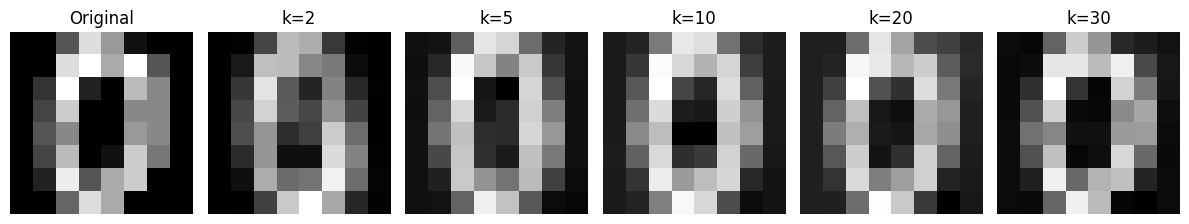

In [3]:
from sklearn.datasets import load_digits
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error

digits = load_digits()
X = MinMaxScaler().fit_transform(digits.data)
dims = [2,5,10,20,30]
models, errors = {}, []
for k in dims:
    p = PCA(n_components=k, svd_solver="full").fit(X)
    Z = p.transform(X); Xr = p.inverse_transform(Z)
    models[k] = Xr
    errors.append(mean_squared_error(X,Xr))
    print(f"k={k}: MSE={errors[-1]:.5f}, noise variance={p.noise_variance_:.5f}, log-likelihood/sample={p.score(X):.5f}")
plt.plot(dims,errors,marker="o"); plt.xlabel("Latent dimensions")
plt.ylabel("Reconstruction MSE"); plt.title("Reconstruction Error"); plt.grid(); plt.show()
fig, ax = plt.subplots(1, len(dims)+1, figsize=(12,3))
ax[0].imshow(digits.images[0],cmap="gray"); ax[0].set_title("Original")
for a,k in zip(ax[1:],dims):
    a.imshow(models[k][0].reshape(8,8),cmap="gray"); a.set_title(f"k={k}")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

**Output / Results:** The program displays the required numerical results, tables, and visualizations for the experiment.

**Results:** Thus the program was successfully verified.

## Experiment 3: Factor Analysis and Latent Factor Interpretation

**Aim: Apply Factor Analysis to wearable-sensor-style data, extract latent factor scores, analyze factor loadings, and visualize hidden factors.**

**Procedure:**
1. Prepare sensor measurements.\n2. Standardize the features.\n3. Apply Factor Analysis.\n4. Extract factor scores and loadings.\n5. Visualize and interpret the latent factors.

Factor loadings:


,Factor 1,Factor 2
Acceleration,0.381,0.842
Movement intensity,0.328,0.848
Walking rhythm,0.802,-0.406
Step frequency,0.792,-0.444
Speed index,0.785,0.358
Duration index,0.773,-0.391


Latent factor scores:


,Factor 1,Factor 2
0,0.394935,-0.219673
1,-0.663550,-1.034492
2,0.465099,0.395407
3,0.209102,0.936595
4,-1.297216,-1.519178


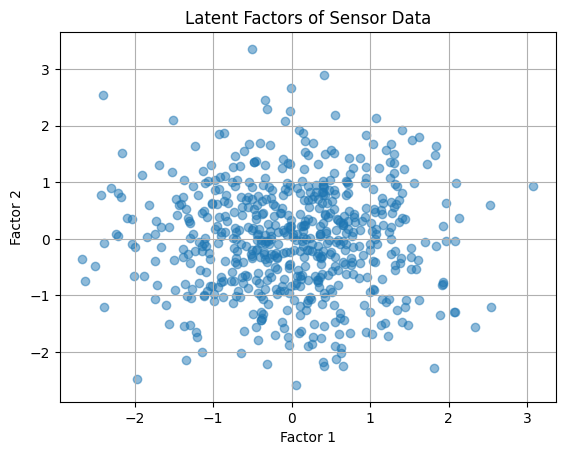

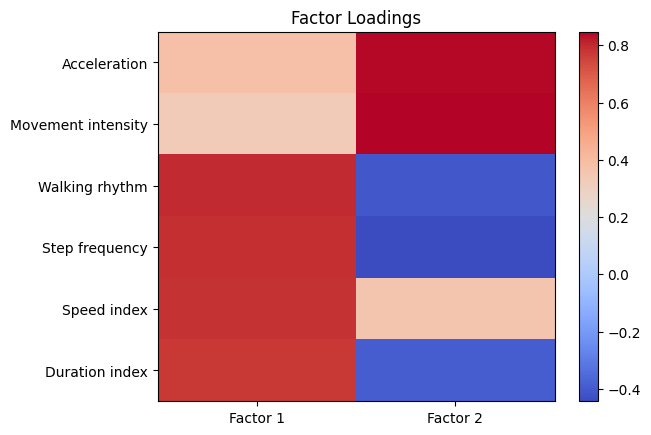

In [4]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import FactorAnalysis

rng=np.random.default_rng(42); n=600
movement=rng.normal(size=n); pattern=rng.normal(size=n); e=rng.normal(scale=.35,size=(n,6))
X=np.c_[.9*movement+e[:,0],.8*movement+e[:,1],.7*pattern+e[:,2],
        .8*pattern+e[:,3],.5*movement+.4*pattern+e[:,4],.6*pattern+e[:,5]]
names=["Acceleration","Movement intensity","Walking rhythm","Step frequency","Speed index","Duration index"]
Xs=StandardScaler().fit_transform(X)
fa=FactorAnalysis(n_components=2,random_state=42)
scores=fa.fit_transform(Xs)
loadings=pd.DataFrame(fa.components_.T,index=names,columns=["Factor 1","Factor 2"])
print("Factor loadings:"); display(loadings.round(3))
print("Latent factor scores:"); display(pd.DataFrame(scores,columns=["Factor 1","Factor 2"]).head())
plt.scatter(scores[:,0],scores[:,1],alpha=.5); plt.xlabel("Factor 1"); plt.ylabel("Factor 2")
plt.title("Latent Factors of Sensor Data"); plt.grid(); plt.show()
plt.imshow(loadings,cmap="coolwarm",aspect="auto"); plt.yticks(range(6),names)
plt.xticks([0,1],["Factor 1","Factor 2"]); plt.colorbar(); plt.title("Factor Loadings"); plt.show()

**Output / Results:** The program displays the required numerical results, tables, and visualizations for the experiment.

**Results:** Thus the program was successfully verified.

## Experiment 4: Independent Component Analysis and Component Visualization

**Aim: Implement FastICA to separate mixed EEG-like signals into independent components, reconstruct the signals, and examine ICA limitations.**

**Procedure:**
1. Generate independent source signals.\n2. Mix the source signals.\n3. Center and scale the mixed signals.\n4. Apply FastICA with different component counts.\n5. Display mixed signals and independent components.\n6. Reconstruct signals and calculate reconstruction error.

Sampling rate: 128 Hz | Mixed shape: (1280, 3) | Component shape: (1280, 3)
Reconstruction MSE: 0.0


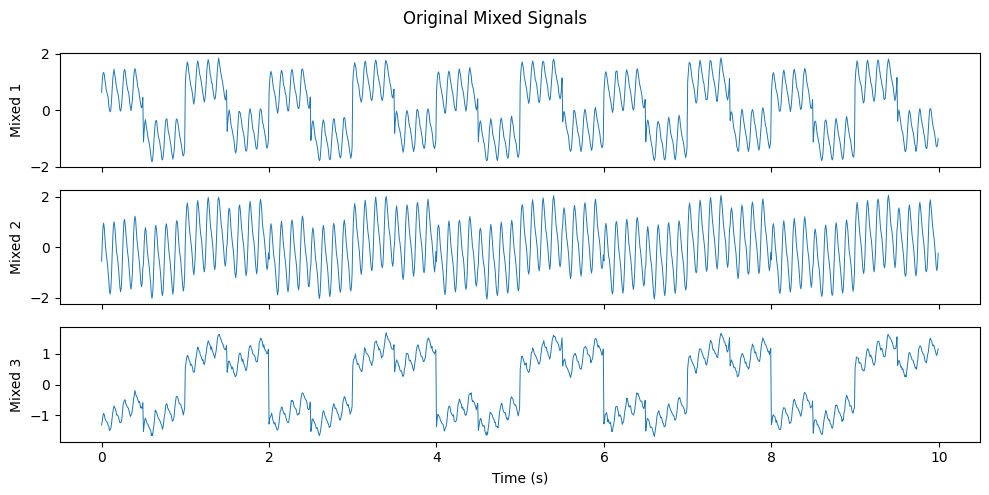

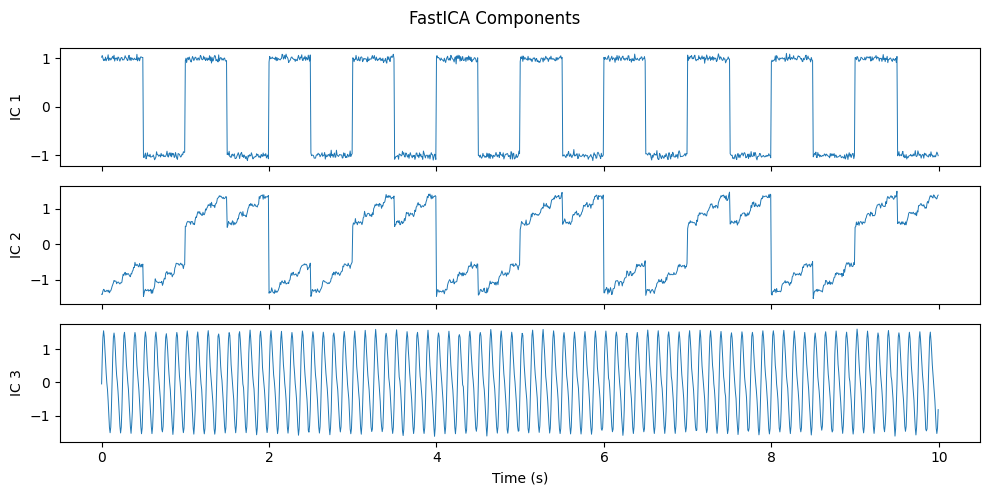

Components: 2 Output shape: (1280, 2)
Components: 3 Output shape: (1280, 3)
ICA component order and sign are not fixed; source interpretation requires domain validation.


In [5]:
from scipy import signal
from sklearn.decomposition import FastICA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

rng=np.random.default_rng(42); fs=128; t=np.arange(0,10,1/fs)
S=np.c_[signal.square(2*np.pi*t),np.sin(2*np.pi*8*t)+.3*np.sin(2*np.pi*16*t),signal.sawtooth(2*np.pi*.5*t)]
S=StandardScaler().fit_transform(S)
A=np.array([[1,.5,.2],[.3,1,.5],[.5,.2,1]])
X=S@A.T+rng.normal(scale=.03,size=S.shape)
X=StandardScaler().fit_transform(X)
ica=FastICA(n_components=3,random_state=42,max_iter=1000)
components=ica.fit_transform(X); reconstructed=ica.inverse_transform(components)
print("Sampling rate:",fs,"Hz | Mixed shape:",X.shape,"| Component shape:",components.shape)
print("Reconstruction MSE:",round(mean_squared_error(X,reconstructed),6))
fig,ax=plt.subplots(3,1,figsize=(10,5),sharex=True)
for i in range(3): ax[i].plot(t,X[:,i],lw=.7); ax[i].set_ylabel(f"Mixed {i+1}")
plt.xlabel("Time (s)"); plt.suptitle("Original Mixed Signals"); plt.tight_layout(); plt.show()
fig,ax=plt.subplots(3,1,figsize=(10,5),sharex=True)
for i in range(3): ax[i].plot(t,components[:,i],lw=.7); ax[i].set_ylabel(f"IC {i+1}")
plt.xlabel("Time (s)"); plt.suptitle("FastICA Components"); plt.tight_layout(); plt.show()
for ncomp in [2,3]:
    temp=FastICA(n_components=ncomp,random_state=42,max_iter=1000).fit_transform(X)
    print("Components:",ncomp,"Output shape:",temp.shape)
print("ICA component order and sign are not fixed; source interpretation requires domain validation.")

**Output / Results:** The program displays the required numerical results, tables, and visualizations for the experiment.

**Results:** Thus the program was successfully verified.

## Experiment 5: Bayesian Network Construction and Visualization

**Aim: Construct and visualize a Bayesian Network for heart-disease-style attributes, estimate CPDs, validate the network, and perform probabilistic inference.**

**Procedure:**
1. Prepare age, chest pain, cholesterol, blood pressure, and target variables.\n2. Discretize the features.\n3. Define a directed acyclic graph.\n4. Estimate CPDs and validate the model.\n5. Visualize the network.\n6. Calculate posterior probabilities for different evidence.

In [6]:
%pip -q install pgmpy

In [7]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import MaximumLikelihoodEstimator
from pgmpy.inference import VariableElimination
import networkx as nx

rng=np.random.default_rng(42); n=1000
age=rng.integers(1,3,n); chest=rng.integers(0,4,n)
chol=rng.integers(1,3,n); bp=rng.integers(1,3,n)
risk=.25*(age==2)+.30*(chest>=2)+.20*(chol==2)+.15*(bp==2)+rng.normal(0,.18,n)
target=(risk>.43).astype(int)
data=pd.DataFrame({"Age":age,"ChestPain":chest,"Cholesterol":chol,"RestingBP":bp,"HeartDisease":target})
print("Synthetic demonstration records (not real patient data):"); display(data.head())
edges=[("Age","Cholesterol"),("Age","RestingBP"),("Age","HeartDisease"),
       ("ChestPain","HeartDisease"),("Cholesterol","HeartDisease"),("RestingBP","HeartDisease")]
model=DiscreteBayesianNetwork(edges)
model.fit(data,estimator=MaximumLikelihoodEstimator)
print("DAG valid:",nx.is_directed_acyclic_graph(model))
print("CPDs consistent:",model.check_model())
for cpd in model.get_cpds(): print(cpd)
plt.figure(figsize=(8,5)); pos=nx.spring_layout(model,seed=42)
nx.draw(model,pos,with_labels=True,node_size=2500,node_color="lightblue",arrowsize=18)
plt.title("Heart Disease Bayesian Network"); plt.show()
ve=VariableElimination(model)
print("Higher-risk evidence posterior:")
print(ve.query(["HeartDisease"],evidence={"Age":2,"ChestPain":3,"Cholesterol":2,"RestingBP":2}))
print("Lower-risk evidence posterior:")
print(ve.query(["HeartDisease"],evidence={"Age":1,"ChestPain":0,"Cholesterol":1,"RestingBP":1}))

Synthetic demonstration records (not real patient data):


,Age,ChestPain,Cholesterol,RestingBP,HeartDisease
0,1,3,2,2,1
1,2,2,1,2,1
2,2,2,1,2,1
3,1,3,1,2,0
4,1,0,2,2,0


TypeError: Estimator should be an instance of a discrete parameter estimator. Pass an initialized estimator, for example `DiscreteMLE()`.

**Output / Results:** The program displays the required numerical results, tables, and visualizations for the experiment.

**Results:** Thus the program was successfully verified.

## Experiment 6: Graphical Model Sampling and Probabilistic Inference

**Aim: Construct the standard Asia Bayesian Network, define benchmark CPDs, generate 1,000 samples, and perform probabilistic inference.**

**Procedure:**
1. Define the eight Asia-network variables and standard edges.\n2. Specify benchmark CPDs.\n3. Validate and visualize the network.\n4. Generate 1,000 samples using forward sampling.\n5. Calculate prior and posterior probabilities.\n6. Compare probabilities under different evidence.

In [ ]:
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.sampling import BayesianNetworkSampling
from pgmpy.inference import VariableElimination
import networkx as nx

edges=[("Asia","Tuberculosis"),("Smoking","LungCancer"),("Smoking","Bronchitis"),
       ("Tuberculosis","Either"),("LungCancer","Either"),("Either","XRay"),
       ("Either","Dyspnea"),("Bronchitis","Dyspnea")]
asia=DiscreteBayesianNetwork(edges)
cpds=[
 TabularCPD("Asia",2,[[.01],[.99]]),
 TabularCPD("Smoking",2,[[.5],[.5]]),
 TabularCPD("Tuberculosis",2,[[.05,.01],[.95,.99]],evidence=["Asia"],evidence_card=[2]),
 TabularCPD("LungCancer",2,[[.10,.01],[.90,.99]],evidence=["Smoking"],evidence_card=[2]),
 TabularCPD("Bronchitis",2,[[.60,.30],[.40,.70]],evidence=["Smoking"],evidence_card=[2]),
 TabularCPD("Either",2,[[1,0,0,0],[0,1,1,1]],evidence=["Tuberculosis","LungCancer"],evidence_card=[2,2]),
 TabularCPD("XRay",2,[[.98,.05],[.02,.95]],evidence=["Either"],evidence_card=[2]),
 TabularCPD("Dyspnea",2,[[.9,.2,.3,.1],[.1,.8,.7,.9]],evidence=["Either","Bronchitis"],evidence_card=[2,2])
]
asia.add_cpds(*cpds)
print("DAG valid:",nx.is_directed_acyclic_graph(asia))
print("CPDs consistent:",asia.check_model())
plt.figure(figsize=(8,5)); pos=nx.spring_layout(asia,seed=42)
nx.draw(asia,pos,with_labels=True,node_size=2300,node_color="lightgreen",arrowsize=18)
plt.title("Standard Asia Bayesian Network"); plt.show()
samples=BayesianNetworkSampling(asia).forward_sample(size=1000,seed=42)
df=pd.DataFrame(samples)
print("Generated sample shape:",df.shape); display(df.head(10))
infer=VariableElimination(asia)
print("Prior Lung Cancer:"); print(infer.query(["LungCancer"]))
print("Lung Cancer given smoker (state 0):"); print(infer.query(["LungCancer"],evidence={"Smoking":0}))
print("Prior Tuberculosis:"); print(infer.query(["Tuberculosis"]))
print("Tuberculosis given Asia visit (state 0):"); print(infer.query(["Tuberculosis"],evidence={"Asia":0}))
df["LungCancer"].value_counts(normalize=True).sort_index().plot(kind="bar",title="Sampled Lung Cancer States")
plt.xlabel("LungCancer state"); plt.ylabel("Proportion"); plt.show()

**Output / Results:** The program displays the required numerical results, tables, and visualizations for the experiment.

**Results:** Thus the program was successfully verified.

## Final Note
All six CO4 experiments are arranged for Google Colab and require no manual dataset upload. Experiments 3 and 4 use synthetic sensor/signal data, and Experiment 5 uses synthetic heart-disease-style records because the standard datasets would require external downloading. Experiment 6 uses the standard Asia Bayesian Network benchmark. Synthetic examples are for laboratory demonstration only and are not real medical records or diagnostic tools.